# Experiment 3: Handle Missing and Categorical Data using Pandas & Scikit-learn

**Aim:** To learn and apply techniques for handling missing values and encoding categorical features using Pandas and Scikit-learn.

**Dataset:** Titanic dataset (`datasets/titanic.csv`). `Age` and `Embarked` contain missing values; `Sex` and `Embarked` are categorical.

In [1]:
# Step 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
import os
os.makedirs("output", exist_ok=True)   # all plots are saved in this folder

In [2]:
# Step 2: Load Titanic dataset
df = pd.read_csv("datasets/titanic.csv")
print("Initial shape:", df.shape)

Initial shape: (891, 12)


In [3]:
# Step 3: Select columns of interest
data = df[['Age', 'Sex', 'Embarked', 'Fare']].copy()
print("Missing values before handling:")
missing_before = data.isnull().sum()
print(missing_before)

Missing values before handling:
Age         177
Sex           0
Embarked      2
Fare          0
dtype: int64


In [4]:
# Step 4: Impute missing 'Age' with mean and 'Embarked' with mode
imputer = SimpleImputer(strategy='mean')
data.loc[:, 'Age'] = imputer.fit_transform(data[['Age']])[:, 0]

imputer_mode = SimpleImputer(strategy='most_frequent')
data.loc[:, 'Embarked'] = imputer_mode.fit_transform(data[['Embarked']])[:, 0]

print("Mean used for Age     :", round(imputer.statistics_[0], 2))
print("Mode used for Embarked:", imputer_mode.statistics_[0])
print("\nMissing values after imputation:")
missing_after = data.isnull().sum()
print(missing_after)

Mean used for Age     : 29.7
Mode used for Embarked: S

Missing values after imputation:
Age         0
Sex         0
Embarked    0
Fare        0
dtype: int64


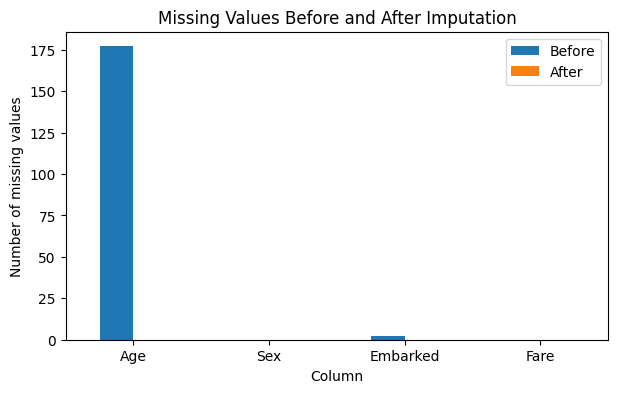

In [5]:
# Missing values before vs after imputation
pd.DataFrame({'Before': missing_before, 'After': missing_after}).plot(kind='bar', figsize=(7, 4))
plt.title('Missing Values Before and After Imputation')
plt.xlabel('Column')
plt.ylabel('Number of missing values')
plt.xticks(rotation=0)
plt.savefig("output/Exp3_missing_values.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
# Step 5: Encode categorical columns (One-Hot Encoding)
data_encoded = pd.get_dummies(data, columns=['Sex', 'Embarked'], dtype=int)
print("Final DataFrame after encoding:")
print(data_encoded.head())
print("\nFinal shape:", data_encoded.shape)

Final DataFrame after encoding:
    Age     Fare  Sex_female  Sex_male  Embarked_C  Embarked_Q  Embarked_S
0  22.0   7.2500           0         1           0           0           1
1  38.0  71.2833           1         0           1           0           0
2  26.0   7.9250           1         0           0           0           1
3  35.0  53.1000           1         0           0           0           1
4  35.0   8.0500           0         1           0           0           1

Final shape: (891, 7)


In [7]:
# Same encoding using Scikit-learn's OneHotEncoder
encoder = OneHotEncoder()
encoded = encoder.fit_transform(data[['Sex', 'Embarked']]).toarray()
print("OneHotEncoder columns:", list(encoder.get_feature_names_out()))
print(encoded[:5])

OneHotEncoder columns: ['Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S']
[[0. 1. 0. 0. 1.]
 [1. 0. 1. 0. 0.]
 [1. 0. 0. 0. 1.]
 [1. 0. 0. 0. 1.]
 [0. 1. 0. 0. 1.]]


## Conclusion
The experiment demonstrated how to identify and handle missing values and encode categorical variables using Pandas and Scikit-learn. Proper preprocessing improves the performance of machine learning models and avoids common training issues.